# Customer Segmentation with K-means

A NumPy implementation of K-means on standardized recency, frequency, and monetary features.

See [project notes](docs/customer-segmentation.md) for setup, methods, and limitations.

Saved outputs are from the original local exploration; restart the kernel and run all cells for a fresh result.


In [43]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

In [44]:
df=pd.read_excel('Online Retail.xlsx')

print(df.shape)
print(df.isnull().sum())
print(df['InvoiceDate'].dtype)


(541909, 8)
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
datetime64[us]


In [45]:
df = df.dropna(subset=['CustomerID'])
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[df['Quantity'] > 0]
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [46]:
df['TotalPrice']=df['Quantity']*df['UnitPrice']

rfm=df.groupby('CustomerID').agg(Recency=('InvoiceDate', lambda x:(df['InvoiceDate'].max()-x.max()).days), 
                                 Frequency=('InvoiceNo', 'nunique'),
                                 Monetary=('TotalPrice', 'sum')
                                ).reset_index()

In [47]:
X = rfm[['Recency', 'Frequency', 'Monetary']].values
mean = X.mean(axis=0)
std = X.std(axis=0)
X_scaled = (X - mean) / std

In [52]:
def initialize_centroids(X, k, random_state=42):
    rng=np.random.default_rng(random_state)
    idx=rng.choice(len(X), size=k, replace=False)
    return X[idx].copy()

def assign_clusters(X, centroids):
    distances=np.linalg.norm(X[:, np.newaxis]-centroids, axis=2)
    return np.argmin(distances, axis=1)

def update_centroids(X, labels, k):
    centroids=np.zeros((k, X.shape[1]))
    for i in range(k):
        points_in_cluster=X[labels==i]
        if len(points_in_cluster)>0:
            centroids[i]=points_in_cluster.mean(axis=0)
    return centroids

def kmeans(X, k, max_iters=100, tol=1e-4, random_state=42):
    centroids=initialize_centroids(X, k, random_state)

    for i in range(max_iters):
        labels=assign_clusters(X, centroids)
        new_centroids=update_centroids(X, labels, k)

        shift=np.linalg.norm(new_centroids-centroids)
        centroids=new_centroids
        if shift<tol:
            print(f"Converged at iteration {i}")
            break
    return centroids, labels

Converged at iteration 1
Converged at iteration 15
Converged at iteration 18
Converged at iteration 19
Converged at iteration 23
Converged at iteration 47
Converged at iteration 38
Converged at iteration 47
Converged at iteration 48
Converged at iteration 79


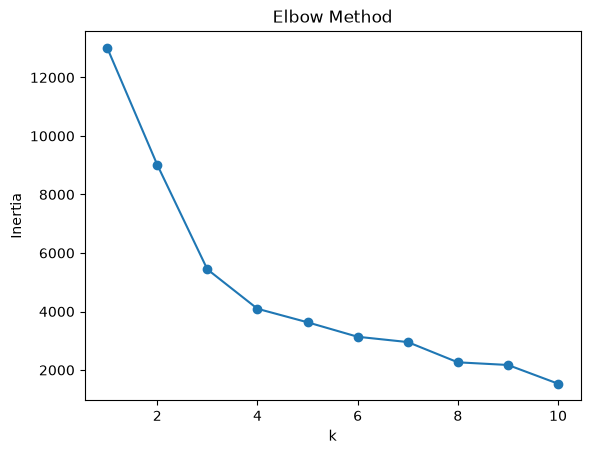

In [53]:
def compute_inertia(X, centroids, labels):
    inertia=0
    for i in range(len(centroids)):
        points=X[labels==i]
        inertia+=np.sum((points-centroids[i])**2)
    return inertia

inertias=[]
for k in range(1, 11):
    centroids, labels=kmeans(X_scaled, k)
    inertias.append(compute_inertia(X_scaled, centroids, labels))

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [55]:
k=4
centroids, labels=kmeans(X_scaled, k)
rfm['Cluster']=labels

cluster_summary = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()
print(cluster_summary)

Converged at iteration 19
            Recency  Frequency       Monetary
Cluster                                      
0         14.638095  22.090476   12482.035333
1         42.869636   3.659024    1350.832661
2          6.384615  82.692308  127338.313846
3        247.469426   1.553151     480.423604


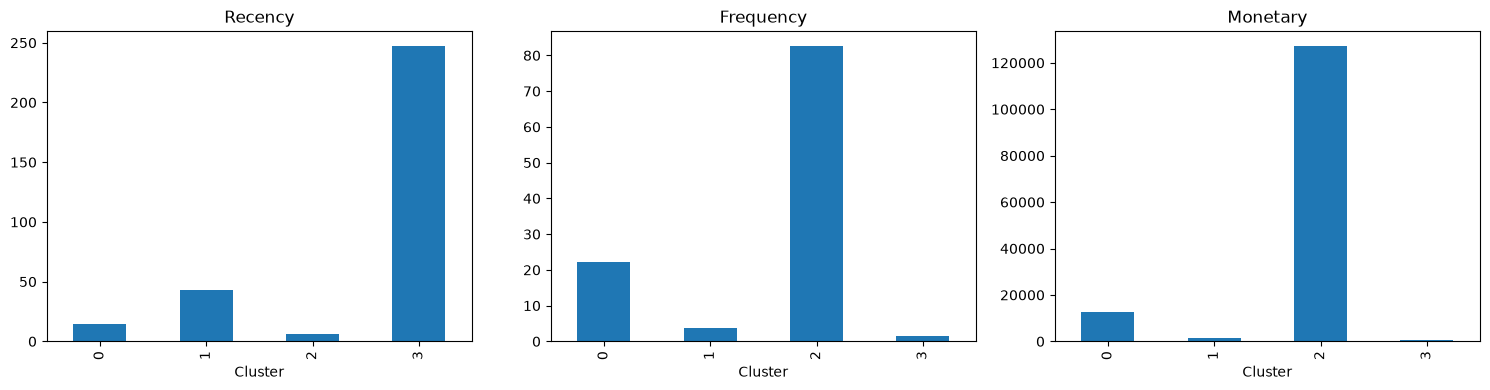

In [56]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, feature in enumerate(['Recency', 'Frequency', 'Monetary']):
    cluster_summary[feature].plot(kind='bar', ax=axes[i], title=feature)
plt.tight_layout()
plt.show()


In [57]:
print(rfm['Cluster'].value_counts())

Cluster
1    3053
3    1063
0     210
2      13
Name: count, dtype: int64
